In [12]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np

# Search Ranking Math
## From word overlap to TF-IDF and cosine similarity

### Abstract

_TODO: write at the end, when the results are ready._

### Table of Contents

* [1. Problem formulation](#chapter1)
* [2. Data](#chapter2)
    * [2.1. Data source and license](#section_2_1)
    * [2.2. Text preprocessing](#section_2_2)
* [3. Baseline: word overlap (Jaccard similarity)](#chapter3)
    * [3.1. Sets, intersection and union](#section_3_1)
    * [3.2. Jaccard similarity](#section_3_2)
    * [3.3. Implementation](#section_3_3)
* [4. TF-IDF](#chapter4)
* [5. Cosine similarity](#chapter5)
* [6. Experiments](#chapter6)
* [7. Limitations](#chapter7)
* [8. Conclusion](#chapter8)
* [9. References](#chapter9)

### 1. Problem formulation <a class="anchor" id="chapter1"></a>

When you search for something, a search engine has to decide which results to show first. There can be thousands or even millions of documents, so it is important to find the most relevant ones. If the first results are not useful, users may not find the information they need and may stop using the search engine.

Let $D = \{d_1, d_2, \dots, d_N\}$ be a collection of $N$ documents and let $q$ be a search query.
A scoring function assigns a relevance score to every document:

$$s(q, d_i) \in \mathbb{R}, \quad i = 1, \dots, N \tag{1}$$

We compute the score for every document and sort the documents by score in descending order: from the highest score to the lowest.

If two documents have the same score, we keep their original order in the collection. This way, the ranking is always the same when the code is run again.

### 2. Data <a class="anchor" id="chapter2"></a>

### 2.1. Data source and license <a class="anchor" id="section_2_1"></a>
We use 40 articles from the English Wikipedia about technologies: programming languages, databases, web & scraping tools and DevOps tools (10 articles per group). The texts are licensed under CC BY-SA 4.0 [1].

The corpus was downloaded once with `collect_data.py` using the official MediaWiki API [2] and saved to `data/articles.json`. The notebook reads only this file, so the results are the same every time it is run.

In [13]:
with open("data/articles.json", encoding="utf-8") as f:
    corpus = json.load(f)

articles = corpus["articles"]
titles = [article["title"] for article in articles]
groups = [article["group"] for article in articles]
texts = [article["text"] for article in articles]

print(f"Source: {corpus['source']}")
print(f"Retrieved: {corpus['retrieved']}")
print(f"Number of articles: {len(articles)}")

Source: English Wikipedia (https://en.wikipedia.org), MediaWiki API
Retrieved: 2026-10-23
Number of articles: 40


How long are the articles? We count the words in each document $d_i$ and compute the average length with the arithmetic mean:

$$\bar{x} = \frac{1}{N} \sum_{i=1}^{N} x_i \tag{2}$$

**Where:**

$N$ - number of documents

$x_i$ - number of words in document $d_i$

Average length: 3805 words
Shortest: GitLab (71 words)
Longest: C (programming language) (8799 words)


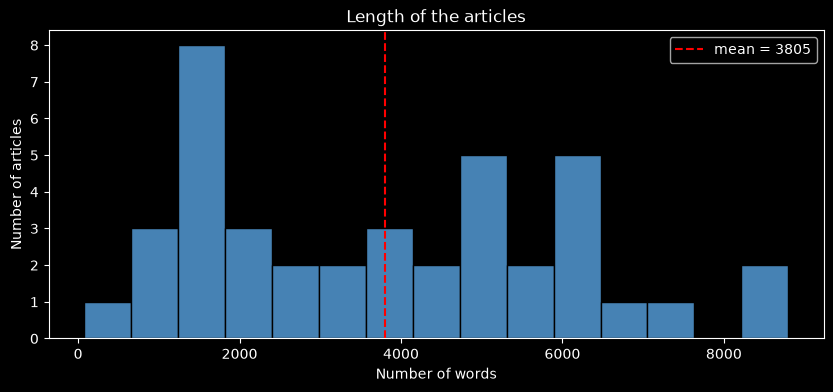

In [14]:
lengths = [len(text.split()) for text in texts]
mean_length = sum(lengths) / len(lengths)

print(f"Average length: {mean_length:.0f} words")
print(f"Shortest: {titles[lengths.index(min(lengths))]} ({min(lengths)} words)")
print(f"Longest: {titles[lengths.index(max(lengths))]} ({max(lengths)} words)")

plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=15, color="steelblue", edgecolor="black")
plt.axvline(mean_length, color="red", linestyle="--", label=f"mean = {mean_length:.0f}")
plt.title("Length of the articles")
plt.xlabel("Number of words")
plt.ylabel("Number of articles")
plt.legend()
plt.show()

The lengths are very different: the longest article is more than 100 times longer than the shortest one. We will come back to this in section 5.

### 2.2. Text preprocessing <a class="anchor" id="section_2_2"></a>
A computer sees `Python`, `python` and `python.` as three different words. Before we compare texts, we turn every text into a list of clean words (**tokens**):

1. Convert all letters to lowercase, so `Python` and `python` are the same word.
2. Remove punctuation, so `language.` becomes `language`.
3. Remove **stopwords**: very common words like `is`, `a`, `the`, `of`. They appear in almost every text and do not tell us anything about its topic.

**Assumption (bag of words):** we only look at which words a text contains, not at their order. For example, "dog bites man" and "man bites dog" give the same tokens. This is a simplification, but it is the base of all methods in this notebook.

In [15]:
STOPWORDS = {
    "a", "an", "the", "and", "or", "but", "if", "of", "to", "in", "on", "at", "by", "for", "with",
    "from", "as", "is", "are", "was", "were", "be", "been", "it", "its", "this", "that", "these",
    "those", "which", "who", "what", "can", "has", "have", "had", "not", "also", "such", "s",
}


def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [word for word in words if word not in STOPWORDS]


assert tokenize("Python is a high-level, general-purpose programming language.") == [
    "python", "high", "level", "general", "purpose", "programming", "language"
]

documents = [tokenize(text) for text in texts]
print(tokenize("Python's design philosophy emphasizes code readability."))

['python', 'design', 'philosophy', 'emphasizes', 'code', 'readability']


### 3. Baseline: word overlap (Jaccard similarity) <a class="anchor" id="chapter3"></a>
The simplest idea for search: a document is relevant if it has many words in common with the query.

### 3.1. Sets, intersection and union <a class="anchor" id="section_3_1"></a>
A **set** is a collection of unique elements. If we turn a text into a set of words, each word appears only once, no matter how many times it is in the text.

For two sets $A$ and $B$:
- **intersection** $A \cap B$ - the words that are in **both** sets
- **union** $A \cup B$ - **all** words from the two sets, without repetitions
- $|A|$ - the number of elements in $A$

In Python, sets have the same operations: `a & b` is the intersection and `a | b` is the union.

q       = ['database', 'python']
d_2     = ['database', 'fast', 'redis']
q & d_2 = ['database']
q | d_2 = ['database', 'fast', 'python', 'redis']


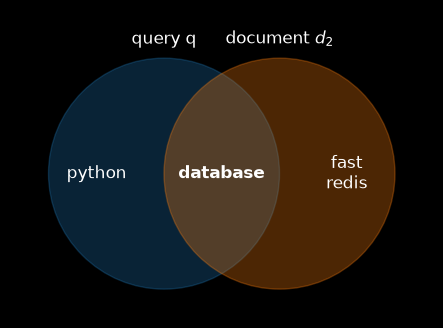

In [16]:
q = set(tokenize("Python database"))
d_2 = set(tokenize("Redis is a fast database"))

print("q       =", sorted(q))
print("d_2     =", sorted(d_2))
print("q & d_2 =", sorted(q & d_2))
print("q | d_2 =", sorted(q | d_2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.add_patch(plt.Circle((-0.6, 0), 1.2, color="tab:blue", alpha=0.3))
ax.add_patch(plt.Circle((0.6, 0), 1.2, color="tab:orange", alpha=0.3))
ax.text(-1.3, 0, "\n".join(sorted(q - d_2)), ha="center", va="center", fontsize=12)
ax.text(0, 0, "\n".join(sorted(q & d_2)), ha="center", va="center", fontsize=12, fontweight="bold")
ax.text(1.3, 0, "\n".join(sorted(d_2 - q)), ha="center", va="center", fontsize=12)
ax.text(-0.6, 1.35, "query q", ha="center", fontsize=12)
ax.text(0.6, 1.35, "document $d_2$", ha="center", fontsize=12)
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(-1.5, 1.7)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

### 3.2. Jaccard similarity <a class="anchor" id="section_3_2"></a>
The **Jaccard similarity** [3] answers the question: *what part of all words are common words?*

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|} \tag{3}$$

**Where:**

$A$ - the set of words in the query $q$

$B$ - the set of words in a document $d_i$

$|A \cap B|$ - number of common words

$|A \cup B|$ - number of all different words in the two texts

We use it as our first scoring function from equation (1): $s(q, d_i) = J(q, d_i)$.

**Special case:** if both sets are empty (for example, a query with only stopwords), the formula becomes $\frac{0}{0}$, which is not defined. Since there are no words, there is no similarity, so we define $J = 0$ in this case.

**Proof that $0 \le J(A, B) \le 1$:**

Every common word is also in the union, so the intersection is a part of the union: $A \cap B \subseteq A \cup B$. Therefore $|A \cap B| \le |A \cup B|$. Both numbers are not negative, so the fraction is between $0$ and $1$. $\blacksquare$

- $J = 0$ when the two texts have no common words.
- $J = 1$ when the two texts have exactly the same set of words.

### 3.3. Implementation <a class="anchor" id="section_3_3"></a>
The function `jaccard` follows equation (3). The function `rank` follows section 1: it computes the score of every document and sorts them in descending order. Python's `sorted` is *stable*, so documents with equal scores keep their original order.

In [17]:
def jaccard(a, b):
    a, b = set(a), set(b)
    union = a | b
    if not union:
        return 0.0
    return len(a & b) / len(union)


def rank(query, documents, score):
    scores = [score(query, document) for document in documents]
    order = sorted(range(len(documents)), key=lambda i: scores[i], reverse=True)
    return [(i, scores[i]) for i in order]

**Check with a hand-computed example.** Query $q$ = "Python database", $d_1$ = "Python is a programming language", $d_2$ = "Redis is a fast database".

After preprocessing: $q = \{python, database\}$, $d_1 = \{python, programming, language\}$, $d_2 = \{redis, fast, database\}$.

$$J(q, d_1) = \frac{|\{python\}|}{|\{python, database, programming, language\}|} = \frac{1}{4} = 0.25$$

$$J(q, d_2) = \frac{|\{database\}|}{|\{python, database, redis, fast\}|} = \frac{1}{4} = 0.25$$

The scores are equal, so $d_1$ stays first because of its original order.

In [18]:
example_query = tokenize("Python database")
example_docs = [tokenize("Python is a programming language"), tokenize("Redis is a fast database")]

assert jaccard(example_query, example_docs[0]) == 0.25
assert jaccard(example_query, example_docs[1]) == 0.25
assert jaccard([], []) == 0.0
assert rank(example_query, example_docs, jaccard) == [(0, 0.25), (1, 0.25)]
print("All checks passed.")

All checks passed.


Now let's search the whole collection:

In [19]:
def show_results(query, score, top=5):
    print(f'Query: "{query}"')
    for position, (i, value) in enumerate(rank(tokenize(query), documents, score)[:top], start=1):
        print(f"{position}. {titles[i]:<35} {groups[i]:<22} score = {value:.4f}")


show_results("python database", jaccard)

Query: "python database"
1. Kibana                              Web & scraping         score = 0.0037
2. Apache Cassandra                    Databases              score = 0.0032
3. Elasticsearch                       Databases              score = 0.0029
4. SQLite                              Databases              score = 0.0025
5. SQL                                 Programming languages  score = 0.0025


The result is surprising: **Kibana** is first, and the article about **Python** is not in the top 5. Let's look at the numbers:

In [ ]:
query = set(tokenize("python database"))
for title in ["Kibana", "Apache Cassandra", "Python (programming language)"]:
    i = titles.index(title)
    document = set(documents[i])
    position = [j for j, _ in rank(list(query), documents, jaccard)].index(i) + 1
    print(f"{title:<32} common words: {sorted(query & document)}, "
          f"different words: {len(document)}, position: {position}")

Long articles have many different words, so the union $|A \cup B|$ in equation (3) is very big and the score becomes very small. Kibana has only one of the two query words, but it is a short article, so it wins. The Python article has more than 1500 different words and it is only at position 30.

So Jaccard has three problems:
1. It prefers **short documents**.
2. Every word has the **same weight**. A rare word like `redis` counts the same as a common word like `data`.
3. It does not count **how many times** a word appears in the text.

In the next section we will see how TF-IDF solves problems 2 and 3. Problem 1 will be solved in section 5 with cosine similarity.

### 4. TF-IDF <a class="anchor" id="chapter4"></a>

_TODO_

### 5. Cosine similarity <a class="anchor" id="chapter5"></a>

_TODO_

### 6. Experiments <a class="anchor" id="chapter6"></a>

_TODO_

### 7. Limitations <a class="anchor" id="chapter7"></a>

_TODO_

### 8. Conclusion <a class="anchor" id="chapter8"></a>

_TODO_

### 9. References <a class="anchor" id="chapter9"></a>
1. Wikipedia, The Free Encyclopedia - 40 articles, listed in `data/articles.json`. Licensed under [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Retrieved 2026-10-23.
2. [MediaWiki Action API](https://www.mediawiki.org/wiki/API:Main_page)
3. Paul Jaccard - "Étude comparative de la distribution florale dans une portion des Alpes et du Jura", Bulletin de la Société Vaudoise des Sciences Naturelles, 1901; <a href="https://en.wikipedia.org/wiki/Jaccard_index">Wikipedia - Jaccard index</a>
